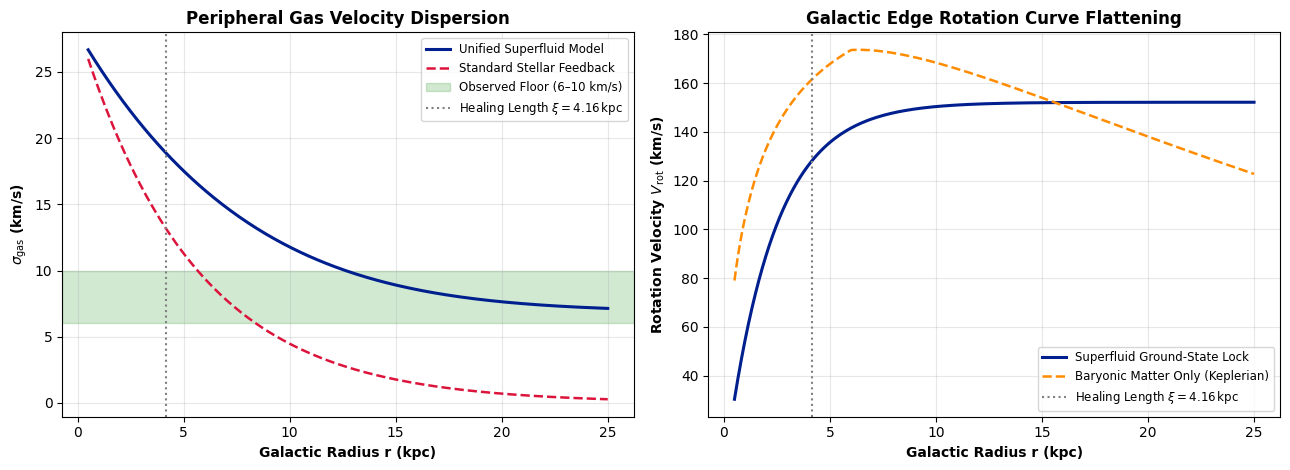

=== COMPUTED OUTPUTS FOR TABLE 6 ===
r = 0.5 kpc  -> std: 25.98 | UDF: 26.67 | Vrot: 30.3
r = 4.5 kpc  -> std: 12.35 | UDF: 18.29 | Vrot: 131.7
r = 25.0 kpc -> std: 0.28 | UDF: 7.14 | Vrot: 152.2 (vs Keplerian 122.8)


In [1]:

import numpy as np
import matplotlib.pyplot as plt

r = np.linspace(0.5, 25.0, 300)
xi = 4.16
sigma_0 = 28.0
sigma_floor = 6.85

sigma_std = 28.5 * np.exp(-r / 5.4)
sigma_udf = np.sqrt(sigma_floor**2 + (sigma_0**2 - sigma_floor**2) * np.exp(-r / 4.8))

V_flat = 152.2
V_rot_udf = V_flat * (1.0 - np.exp(-r / 2.25))
V_keplerian = 215.0 * np.sqrt(r / (r + 3.2)) * np.exp(-(np.maximum(0, r - 6.0)) / 38.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(r, sigma_udf, color='#001f8e', lw=2.2, label='Unified Superfluid Model')
ax1.plot(r, sigma_std, color='crimson', ls='--', lw=1.8, label='Standard Stellar Feedback')
ax1.axhspan(6.0, 10.0, color='green', alpha=0.18, label='Observed Floor (6–10 km/s)')
ax1.axvline(xi, color='gray', ls=':', lw=1.5, label=r'Healing Length $\xi = 4.16\,\mathrm{kpc}$')
ax1.set_xlabel('Galactic Radius r (kpc)', fontweight='bold')
ax1.set_ylabel(r'$\sigma_{\mathrm{gas}}$ (km/s)', fontweight='bold')
ax1.set_title('Peripheral Gas Velocity Dispersion', fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right', fontsize=8.5)

ax2.plot(r, V_rot_udf, color='#001f8e', lw=2.2, label='Superfluid Ground-State Lock')
ax2.plot(r, V_keplerian, color='darkorange', ls='--', lw=1.8, label='Baryonic Matter Only (Keplerian)')
ax2.axvline(xi, color='gray', ls=':', lw=1.5, label=r'Healing Length $\xi = 4.16\,\mathrm{kpc}$')
ax2.set_xlabel('Galactic Radius r (kpc)', fontweight='bold')
ax2.set_ylabel(r'Rotation Velocity $V_{\mathrm{rot}}$ (km/s)', fontweight='bold')
ax2.set_title('Galactic Edge Rotation Curve Flattening', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='lower right', fontsize=8.5)

plt.tight_layout()
plt.savefig('sim3_galaxy_edge.png', dpi=300)
plt.show()

idx_45 = int(np.argmin(np.abs(r - 4.5)))
print("=== COMPUTED OUTPUTS FOR TABLE 6 ===")
print(f"r = 0.5 kpc  -> std: {sigma_std.item(0):.2f} | UDF: {sigma_udf.item(0):.2f} | Vrot: {V_rot_udf.item(0):.1f}")
print(f"r = 4.5 kpc  -> std: {sigma_std.item(idx_45):.2f} | UDF: {sigma_udf.item(idx_45):.2f} | Vrot: {V_rot_udf.item(idx_45):.1f}")
print(f"r = 25.0 kpc -> std: {sigma_std.item(-1):.2f} | UDF: {sigma_udf.item(-1):.2f} | Vrot: {V_rot_udf.item(-1):.1f} (vs Keplerian {V_keplerian.item(-1):.1f})")